# Aprendizado de Máquina para Suporte à Decisão na Governança Operacional de Equipes de Tecnologia — v2

**Trabalho de Conclusão de Curso – MBA em Data Science e Analytics (USP/Esalq)**
Autora: Aline Oliveira da Silveira · Orientador: Ricardo Theodoro

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/alineosilveira/tcc-governanca-operacional-ml-v2/blob/main/TCC_Analise_e_Modelos_v2.ipynb)

Esta é a **versão 2** do trabalho. Ela usa uma nova fonte de dados: uma extração própria e completa do **Jira público da Apache Software Foundation**, coletada em 25/10/2026. A versão 1 ([repositório v1](https://github.com/alineosilveira/tcc-governanca-operacional-ml)) usou a base TAWOS, e **nenhum resultado da v1 é reaproveitado aqui**.

O notebook foi **executado localmente** e salvo com os resultados. A leitura dispensa os dados brutos (Modo 1 — consulta). Para reexecutar, veja `docs/reproducao.md` (Modo 2).

## Sumário
1. Apresentação
2. Coleta dos dados
3. Preparação dos dados
4. Análise exploratória
5. Releases × Bugs (H1)
6. Tempo de correção (H2)
7. Retrabalho (reaberturas)
8. Governança operacional (composição das demandas)
9. Modelagem preditiva
10. Conclusões e limitações

# 1. Apresentação

**Tema.** Uso de analytics e aprendizado de máquina sobre registros de demandas de desenvolvimento de software para apoiar decisões de governança operacional de equipes de tecnologia.

**Contexto.** Equipes de tecnologia registram em rastreadores de issues (como o Jira) as releases publicadas, os defeitos encontrados, o ciclo de correção e as reaberturas. Esses registros permitem estudar o risco de releases, a previsibilidade das correções e o retrabalho, desde que suas limitações sejam respeitadas: campos opcionais, workflows diferentes por projeto e histórico incompleto.

**Objetivo geral.** Avaliar se, e em que condições, os registros históricos do Jira permitem descrever e prever indicadores de governança operacional, usando técnicas ensinadas no MBA.

**Objetivos específicos** (escopo da pesquisa original, ajustado pelo diagnóstico de viabilidade):

| # | Objetivo | Situação nesta versão |
|---|---|---|
| 1 | Releases × bugs registrados após a publicação | **Confirmatório (H1)**: vínculo explícito por Affects Version |
| 2 | Tempo de correção dos bugs | **Confirmatório (H2)**: previsão da faixa de tempo na abertura |
| 3 | Planejamento e execução de sprints | **Fora do escopo** (dados insuficientes: só 16 projetos, Agile API indisponível) |
| 4 | Distribuição do trabalho | Exploratório: composição das demandas. **Horas não utilizadas** (registros automáticos). |
| 5 | Retrabalho e criticidade | Exploratório: reaberturas e estabilidade. Criticidade **sem campo estruturado suficiente**. |

**Hipóteses.**
- **H1:** características da release conhecidas na publicação (tamanho, composição, tipo de versão, cadência) estão associadas à quantidade de bugs vinculados a ela nos 180 dias seguintes.
- **H2:** atributos conhecidos na abertura de um bug permitem prever a faixa de tempo até a primeira correção melhor do que uma regra simples por projeto.

**Escopo e unidade de análise.** O **projeto Apache é a unidade primária**: cada indicador é calculado por projeto, e a consolidação é uma segunda camada que controla o efeito de projeto. Os resultados são **associações observacionais**, não relações de causa e efeito.

**Fonte.** `https://issues.apache.org/jira`, API REST v2, com acesso anônimo e somente leitura.

In [1]:
# Configuração: caminhos por variáveis de ambiente (padrão: pastas irmãs do repositório)
import os, json, shutil, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_rows", 30); pd.set_option("display.max_columns", 30); pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

REPO = Path.cwd()
DATA = Path(os.environ.get("ALINE_JIRA_DATA_DIR", REPO.parent / "data" / "apache_jira"))
EVID = Path(os.environ.get("ALINE_EVIDENCIAS_DIR", REPO.parent / "data" / "derivados" / "evidencias"))
BASES = Path(os.environ.get("ALINE_BASES_DIR", REPO.parent / "data" / "derivados" / "bases"))
TAB, GRA, COL = REPO / "resultados" / "tabelas", REPO / "resultados" / "graficos", REPO / "resultados" / "coleta"
for d in (TAB, GRA, COL):
    d.mkdir(parents=True, exist_ok=True)
for p in (DATA / "manifest.json", EVID / "projetos_caracterizacao.csv", BASES / "base_bugs_ciclos.csv"):
    if not p.exists():
        raise FileNotFoundError(f"{p.name} não encontrado: este ambiente está em modo consulta (ver docs/reproducao.md).")

DATA_END = pd.Timestamp("2026-10-25", tz="UTC")   # fim da observação (data do snapshot)
SINCE = pd.Timestamp("2020-01-01", tz="UTC")      # início do período principal
TRAIN_END = pd.Timestamp("2024-01-01", tz="UTC")  # treino: T0 em 2020-2023; teste: T0 >= 2024
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def ts(s):
    return pd.to_datetime(s, utc=True, errors="coerce", format="ISO8601")

def salvar_fig(nome):
    plt.tight_layout(); plt.savefig(GRA / f"{nome}.png", dpi=110, bbox_inches="tight"); plt.show()

def salvar_tab(df, nome):
    df.to_csv(TAB / f"{nome}.csv", index=False, encoding="utf-8"); return df

def pct(a, b):
    return round(100 * a / b, 1) if b else np.nan

print("Snapshot:", DATA.name, "| evidências:", EVID.name, "| bases:", BASES.name)

Snapshot: apache_jira | evidências: evidencias | bases: bases


# 2. Coleta dos dados

**Pergunta.** Como os dados foram obtidos, e a coleta é completa e íntegra?

**Script.** `src/coleta/apache_jira_extract.py`. A coleta **não** é reexecutada aqui; o notebook lê o `manifest.json` produzido por ela.

| Etapa | Descrição |
|---|---|
| Endpoint | `GET /rest/api/2/search` (Jira Server 10.3.26), acesso anônimo |
| JQL | `created >= "2020-01-01" OR updated >= "2020-01-01" OR resolution IS EMPTY` |
| Divisão do trabalho | 50 janelas disjuntas de `created` (≤ 20 mil issues cada), paginadas em paralelo (4 a 8 requisições simultâneas, ≤ 8 req/s) |
| Paginação | `maxResults=1000` (limite real do servidor), `fields=*all`, `expand=changelog` |
| Dados associados | Changelog completo na busca; worklogs (> 20) e comentários (> 1000) truncados completados por endpoint dedicado; versões por projeto |
| Robustez | Backoff exponencial com jitter, `Retry-After`, sem retry em 4xx permanentes, checkpoint por página com retomada |
| Deduplicação | Por **id** da issue; reconciliação de ids × contagem em cada janela |
| Saídas | `issues.jsonl`, `changelog.jsonl`, `comments.jsonl`, `worklogs.jsonl`, `versions.jsonl`, `issue_versions.jsonl`, `projects.jsonl`, `fields.json`, `manifest.json`, `errors.jsonl` |

**Reprodução:** `python src/coleta/apache_jira_extract.py` (nova coleta, com resultados possivelmente diferentes, porque o Jira continua ativo) e `python src/coleta/quality_report.py` (verificação de integridade).

In [2]:
m = json.load(open(DATA / "manifest.json", encoding="utf-8"))
# cópia publicável do manifesto (sem caminhos locais sensíveis) e do relatório de qualidade
pub = {k: m[k] for k in ["extraction_started_utc", "manifest_written_utc", "base_url", "server_info", "api", "global_jql",
                         "parameters", "probes", "plan", "units_total", "units_done", "units_failed", "pages_fetched",
                         "global_total_at_end", "versions_projects", "boards_api", "merge", "completion"]}
pub["units"] = [{k: u.get(k) for k in ("id", "lo", "hi", "planned", "final_total", "unique_ids", "pages", "reconciled")}
                for u in m["units"]]
json.dump(pub, open(COL / "manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1)
shutil.copy(DATA / "data_quality_report.md", COL / "data_quality_report.md")

mg = m["merge"]
coleta = pd.DataFrame([
    ("Início / fim da extração (UTC)", f'{m["extraction_started_utc"]} / {m["manifest_written_utc"]}'),
    ("Servidor", f'{m["server_info"]["serverTitle"]} {m["server_info"]["version"]} ({m["server_info"]["deploymentType"]})'),
    ("Estado de conclusão", m["completion"]),
    ("Janelas (unidades) concluídas", f'{m["units_done"]}/{m["units_total"]}'),
    ("Páginas de busca", m["pages_fetched"]),
    ("Total da JQL no plano / ao final", f'{m["plan"]["global_total"]:,} / {m["global_total_at_end"]:,}'),
    ("Issues únicas gravadas", f'{mg["unique_issues"]:,}'),
    ("Duplicatas removidas", mg["duplicate_issue_records_removed"]),
    ("Históricos de changelog", f'{mg["changelog_histories"]:,}'),
    ("Comentários / worklogs", f'{mg["comments"]:,} / {mg["worklogs"]:,}'),
    ("Versões (de 674 projetos)", f'{mg["versions"]:,}'),
    ("Dados associados faltantes após retentativas", sum(mg["associated_missing"].values())),
], columns=["Indicador", "Valor"])
coleta

,Indicador,Valor
0,Início / fim da extração (UTC),2026-10-25T20:22:57Z / 2026-10-25T21:57:01Z
1,Servidor,ASF Jira 10.3.26 (Server)
2,Estado de conclusão,complete
3,Janelas (unidades) concluídas,50/50
4,Páginas de busca,587
5,Total da JQL no plano / ao final,"561,363 / 561,369"
6,Issues únicas gravadas,"561,369"
7,Duplicatas removidas,0
8,Históricos de changelog,"6,464,445"
9,Comentários / worklogs,"1,991,188 / 843,975"


### 2.1 Verificação de integridade

**Método.** São quatro conferências:
1. Cada janela compara os ids únicos baixados com a contagem refeita ao final.
2. O total da API é comparado com os registros gravados, para changelog, comentários e worklogs.
3. Os erros são classificados por fase e por retentativa.
4. As sondagens de endpoints opcionais são registradas.

In [3]:
u = pd.DataFrame(pub["units"])
integ = pd.DataFrame({
    "janelas": [len(u)],
    "janelas com ids únicos = contagem final": [int((u["unique_ids"] == u["final_total"]).sum())],
    "issues planejadas": [int(u["planned"].sum())],
    "issues ao final": [int(u["final_total"].sum())],
})
display(integ)
err = pd.read_json(DATA / "errors.jsonl", lines=True)
err["tipo"] = np.where(err["status"].isna(), "rede (desconexão/timeout)", "HTTP " + err["status"].astype("Int64").astype(str))
display(err.groupby(["phase", "tipo", "retried"]).size().rename("ocorrências").reset_index())
print("Sondagens:", {k: v for k, v in m["probes"].items() if k != "maxResults_requested_5000"},
      "| maxResults pedido 5000 → devolvido", m["probes"]["maxResults_requested_5000"]["returned_maxResults"])

,janelas,janelas com ids únicos = contagem final,issues planejadas,issues ao final
0,50,50,561363,561369


,phase,tipo,retried,ocorrências
0,boards,HTTP 401,False,1
1,extras,rede (desconexão/timeout),True,25
2,inspect,HTTP 401,False,2
3,inspect,HTTP 404,False,1
4,issues,rede (desconexão/timeout),True,8
5,versions,rede (desconexão/timeout),True,1


Sondagens: {'global_total': 561363, 'agile_board': 401, 'worklog_updated': 401, 'issue_changelog_endpoint': 404} | maxResults pedido 5000 → devolvido 1000


**Interpretação.**
- **Completude:** a coleta está completa. As 50 janelas conferem com a contagem final, não há duplicatas, e o changelog, os comentários e os worklogs foram integralmente recuperados.
- **Erros:** os erros de rede foram todos retentados com sucesso. Os HTTP 401/404 são sondagens esperadas: a Agile API e `/worklog/updated` exigem autenticação, e `/issue/{key}/changelog` não existe nesta versão do servidor.
- **Totais:** o total cresceu 6 issues entre o plano e o fim, porque a base continua ativa.

**Limitações.**
- **Visibilidade:** só o que é público para acesso anônimo foi coletado; issues restritas e projetos arquivados não aparecem.
- **Recorte:** issues anteriores a 2020 só entram se estavam abertas ou foram atualizadas depois de 2020, o que gera viés de seleção. Por isso o período principal é a partir de 2020.

# 3. Preparação dos dados

**Pergunta.** Como os ~21 GB de JSONL viram bases analíticas confiáveis e sem informação futura?

A preparação é feita por **scripts externos**, em ordem `01 → 03 → 04 → 05 → 06 → 07`. A linhagem completa está em `docs/linhagem_dados.md` e as regras em `docs/decisoes_metodologicas.md`.

| Script | Objetivo | Entradas | Saídas | Regras / filtros principais |
|---|---|---|---|---|
| `src/preparacao/01_projetar_base.py` | Projeção compacta em uma passagem | JSONL brutos | `issues_c.csv`, `changelog_c.csv`, `worklogs_c.csv`, `comments_c.csv` | ~45 atributos por issue; changelog só de campos relevantes; pessoas → hash com sal local |
| `src/analise/03_diagnostico_cobertura.py` | Cobertura e períodos | cache, `versions.jsonl` | evidências agregadas (tipos por ano, worklogs, criticidade) | identifica contas automáticas |
| `src/analise/04_caracterizacao_por_projeto.py` | **Base A**: projetos | cache, evidências | `projetos_caracterizacao.csv`, `projetos_viabilidade_modelos.csv` | split comum; critérios de modelo individual |
| `src/preparacao/05_validar_regras_negocio.py --bases` | **Bases B–E** | cache, `versions.jsonl` | `base_releases.csv`, `base_bug_release.csv`, `base_bugs_ciclos.csv`, `base_reaberturas.csv` | Affects Version por ID; classes A/B/C/D; B1/B2/B3; reabertura por categoria de status |
| `src/preparacao/06_validar_pendencias.py --bases` | Níveis de evidência | cache, `versions.jsonl` | `base_vinculos_evidencia.csv`, `base_reaberturas_rapidas.csv` | reconstrução reversa do campo Version; reaberturas rápidas |
| `src/preparacao/07_bases_modelagem.py` | Bases de modelagem | cache, bases 05/06 | `modelo_bugs_faixa.csv`, `modelo_releases.csv` | features em T0; split cronológico |

Tratamentos comuns:
- **Datas:** em UTC.
- **Criação inválida:** datas de criação anteriores a 2000 (2 issues importadas) são excluídas.
- **Ausência de dado:** ausência de campo = "sem dado", nunca zero.
- **Deduplicação:** por id de issue, par (bug, versão) e id de versão.
- **Estado em T0:** é reconstruído pelo changelog, nunca pelo estado atual.

In [4]:
def chk(nome, chaves):
    df = pd.read_csv(BASES / nome, dtype=str, usecols=chaves)
    return {"base": nome, "linhas": len(df), "chave": "+".join(chaves),
            "chaves duplicadas": int(df.duplicated(chaves).sum()), "chave com valor ausente": int(df[chaves].isna().any(axis=1).sum())}

bases_chk = pd.DataFrame([
    chk("base_releases.csv", ["version_id"]),
    chk("base_bug_release.csv", ["issue_id", "version_id"]),
    chk("base_bugs_ciclos.csv", ["issue_id"]),
    chk("base_vinculos_evidencia.csv", ["issue_id", "version_id"]),
    chk("base_reaberturas.csv", ["issue_id", "t_reabertura"]),
    chk("modelo_bugs_faixa.csv", ["issue_id"]),
    chk("modelo_releases.csv", ["version_id"]),
])
salvar_tab(bases_chk, "preparacao_verificacao_chaves")

,base,linhas,chave,chaves duplicadas,chave com valor ausente
0,base_releases.csv,6018,version_id,0,0
1,base_bug_release.csv,75033,issue_id+version_id,0,0
2,base_bugs_ciclos.csv,114556,issue_id,0,0
3,base_vinculos_evidencia.csv,175163,issue_id+version_id,0,0
4,base_reaberturas.csv,5022,issue_id+t_reabertura,0,0
5,modelo_bugs_faixa.csv,114556,issue_id,0,0
6,modelo_releases.csv,4626,version_id,0,0


**Unidades estatísticas das bases.**

| Base | Unidade | População | Período |
|---|---|---|---|
| A `projetos_caracterizacao` | projeto | 650 projetos com issues | eventos desde 2020 |
| B `base_releases` | release (versão `released` com `releaseDate`) | todas as releases do inventário | T0 de 2020 a 2026-10-25 |
| C `base_bug_release` / `base_vinculos_evidencia` | par (bug, versão) por Affects Version | bugs coletados × releases do período / todos os vínculos atuais | — |
| D `base_bugs_ciclos` | bug | bugs criados desde 2020 | até 2026-10-25 |
| E `base_reaberturas` | evento de reabertura | bugs criados desde 2020 | até 2026-10-25 |
| F demandas por tipo (Cap. 8) | projeto × ano × tipo | issues criadas desde 2020 | 2020–2026 |

**Interpretação.** Nenhuma base tem chave duplicada. Por isso os joins entre elas não multiplicam bugs nem versões: um bug ligado a várias versões aparece uma vez por versão, e os bugs distintos são sempre contados com `nunique`.

In [5]:
B = pd.read_csv(BASES / "base_bugs_ciclos.csv", dtype={"issue_id": str})
for c in ("created", "t_b1", "t_b2", "t_b3", "t_last_close"):
    B[c] = ts(B[c])
falt = pd.DataFrame({
    "campo": ["resolution (vazia = aberto)", "t_b1 (1ª resolução)", "t_b2 (1º fechamento)", "t_b3 (1ª correção Fixed)"],
    "registros sem valor": [int((B["resolution"].isna()).sum()), int(B["t_b1"].isna().sum()), int(B["t_b2"].isna().sum()), int(B["t_b3"].isna().sum())],
})
falt["% dos bugs desde 2020"] = (100 * falt["registros sem valor"] / len(B)).round(1)
print(f"Bugs criados desde 2020: {len(B):,} em {B['project'].nunique()} projetos")
falt

Bugs criados desde 2020: 114,556 em 412 projetos


,campo,registros sem valor,% dos bugs desde 2020
0,resolution (vazia = aberto),26977,23.50
1,t_b1 (1ª resolução),26493,23.10
2,t_b2 (1º fechamento),26391,23.00
3,t_b3 (1ª correção Fixed),44181,38.60


**Interpretação.**
- **Valores ausentes nos tempos:** são censura, ou seja, bugs ainda abertos ou encerrados sem correção. Não são erros, e não recebem data final inventada.
- **Datas recuperadas pelo histórico:** o changelog permitiu datar a primeira resolução e o primeiro fechamento em 100% dos bugs resolvidos, e recuperou 586 bugs sem `resolutiondate` (ver Cap. 6).

# 4. Análise exploratória

**Pergunta.** Como os dados se distribuem entre projetos, tipos e tempo, e quão diferentes são os projetos?

**Dados:** Base A (`projetos_caracterizacao.csv`) e evidências agregadas do script 03.

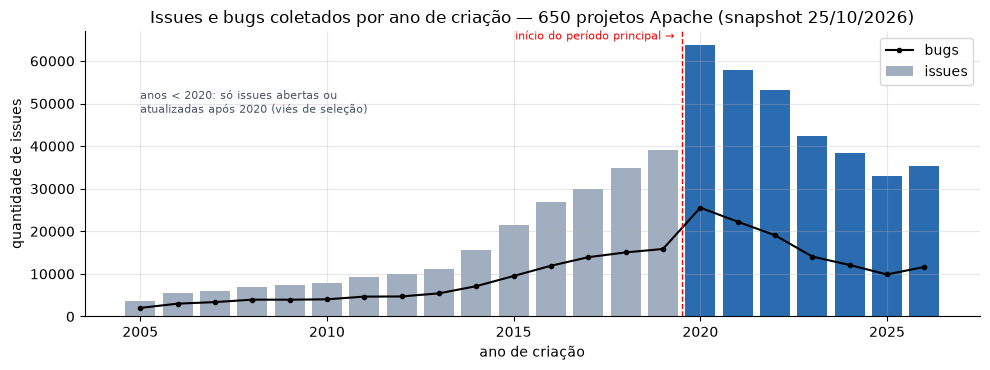

Projetos com issues: 650 | issues criadas desde 2020: 323,695 | bugs desde 2020: 114,556


In [6]:
P = pd.read_csv(EVID / "projetos_caracterizacao.csv")
P = P.drop(columns=[c for c in P.columns if "sprint" in c.lower()])          # sprints fora do escopo
salvar_tab(P, "base_A_projetos_caracterizacao")
anos = pd.read_csv(EVID / "base_issues_por_ano_criacao.csv")
anos = anos[(anos["cyear"] >= 2005) & (anos["cyear"] <= 2026)]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(anos["cyear"], anos["issues"], color=np.where(anos["cyear"] >= 2020, "#2b6cb0", "#a0aec0"), label="issues")
ax.plot(anos["cyear"], anos["bugs"], "k.-", label="bugs")
ax.axvline(2019.5, color="red", ls="--", lw=1); ax.text(2019.3, anos["issues"].max() * 1.02, "início do período principal →", color="red", fontsize=8, ha="right")
ax.set_title("Issues e bugs coletados por ano de criação — 650 projetos Apache (snapshot 25/10/2026)")
ax.set_xlabel("ano de criação"); ax.set_ylabel("quantidade de issues"); ax.legend()
ax.text(2005, anos["issues"].max() * .75, "anos < 2020: só issues abertas ou\natualizadas após 2020 (viés de seleção)", fontsize=8, color="#4a5568")
salvar_fig("cap4_issues_por_ano")
print(f"Projetos com issues: {len(P)} | issues criadas desde 2020: {P['issues_criadas>=2020'].sum():,} | bugs desde 2020: {P['bugs>=2020'].sum():,}")

,recorte,% das issues desde 2020
0,top 10 projetos,45.30
1,top 50 projetos,81.30
2,demais,18.70


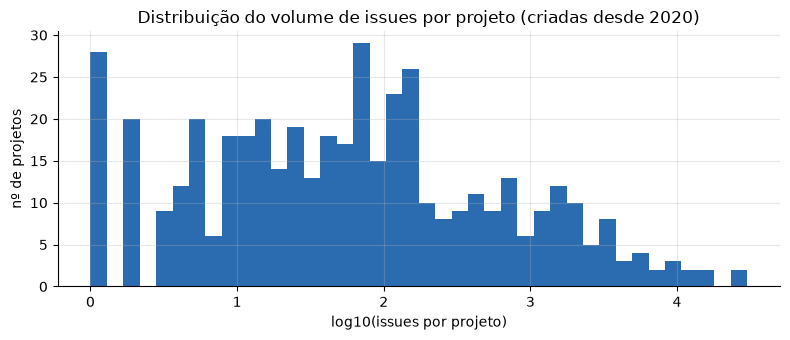

In [7]:
s = P.sort_values("issues_criadas>=2020", ascending=False)["issues_criadas>=2020"]
conc = pd.DataFrame({"recorte": ["top 10 projetos", "top 50 projetos", "demais"],
                     "% das issues desde 2020": [pct(s.head(10).sum(), s.sum()), pct(s.head(50).sum(), s.sum()), pct(s.iloc[50:].sum(), s.sum())]})
display(conc)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(np.log10(s[s > 0]), bins=40, color="#2b6cb0")
ax.set_title("Distribuição do volume de issues por projeto (criadas desde 2020)")
ax.set_xlabel("log10(issues por projeto)"); ax.set_ylabel("nº de projetos")
salvar_fig("cap4_volume_por_projeto")

**Interpretação.** O volume é muito concentrado: poucos projetos grandes respondem por grande parte das issues. Por isso as análises são **por projeto**, e as visões consolidadas controlam o efeito de projeto.

### 4.1 Cobertura dos campos por projeto

A cobertura de cada campo é calculada **dentro de cada projeto** (projetos com 100 bugs ou mais desde 2020). As porcentagens globais escondem essa variação.

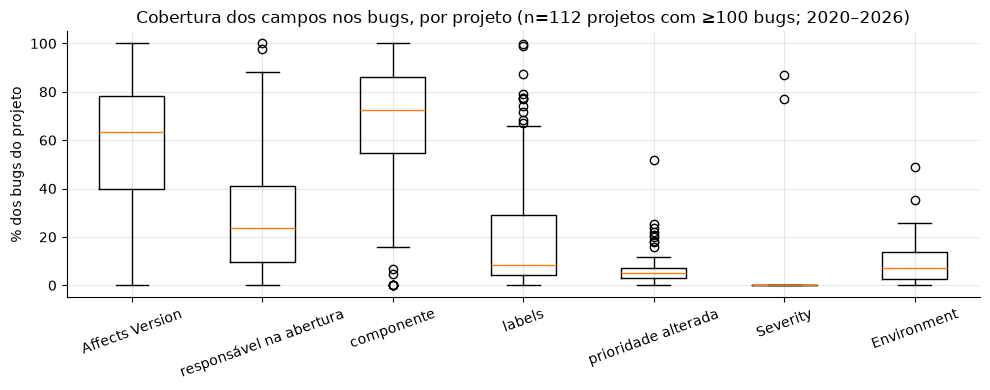

,campo,count,mean,std,min,10%,50%,90%,max
0,Affects Version,112.00,57.70,26.00,0.00,18.80,63.30,86.20,100.00
1,responsável na abertura,112.00,27.20,21.00,0.00,3.30,23.80,55.10,100.00
2,componente,112.00,67.40,24.90,0.00,40.10,72.40,95.70,100.00
3,labels,112.00,21.30,26.00,0.00,1.90,8.60,65.90,99.70
4,prioridade alterada,112.00,6.40,6.50,0.00,1.30,5.20,10.80,51.60
5,Severity,112.00,1.50,10.90,0.00,0.00,0.00,0.00,86.80
6,Environment,112.00,9.30,8.10,0.00,1.30,7.20,19.00,48.90


In [8]:
cols = {"affects_version_%": "Affects Version", "assignee_na_abertura_%": "responsável na abertura",
        "componente_%": "componente", "labels_%": "labels", "prioridade_alterada_%": "prioridade alterada",
        "severity_%": "Severity", "environment_%": "Environment"}
Pg = P[P["bugs>=2020"] >= 100]
cob = Pg[list(cols)].rename(columns=cols)
fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([cob[c].dropna() for c in cob.columns], tick_labels=cob.columns)
ax.set_title(f"Cobertura dos campos nos bugs, por projeto (n={len(Pg)} projetos com ≥100 bugs; 2020–2026)")
ax.set_ylabel("% dos bugs do projeto"); plt.xticks(rotation=20)
salvar_fig("cap4_cobertura_campos_projeto")
salvar_tab(cob.describe(percentiles=[.1, .5, .9]).T.reset_index().rename(columns={"index": "campo"}).round(1), "cap4_cobertura_campos")

**Interpretação.**
- **Campos que variam entre projetos:** Affects Version, componente e responsável na abertura existem, mas o preenchimento muda muito de um projeto para outro. Uma variável pode ser informativa num projeto e quase constante em outro.
- **Severity e Environment:** praticamente não são usados, por isso **criticidade estruturada não é analisável**.

### 4.2 Séries interrompidas, versionamento modular e heterogeneidade

In [9]:
ser = P[P["serie_interrompida(>=100 bugs; nenhum nos ultimos 12m)"]].sort_values("bugs>=2020", ascending=False)
print(f"Projetos com série interrompida (≥100 bugs e nenhum bug nos últimos 12 meses): {len(ser)} — {ser['bugs>=2020'].sum():,} bugs desde 2020")
display(ser[["projeto", "bugs>=2020", "ultimo_bug_criado"]].head(10))
mod = P[(P["releases>=2020"] >= 10)]
print(f"Projetos com ≥10 releases desde 2020: {len(mod)}; com ≥30% de nomes modulares: {(mod['nomes_modulares_%'] >= 30).sum()}")
display(mod.sort_values("releases>=2020", ascending=False)[["projeto", "releases>=2020", "nomes_modulares_%", "prefixos_modulo_distintos", "overlap_90d_%"]].head(8))
het = pd.read_csv(EVID / "heterogeneidade_entre_projetos.csv")
salvar_tab(het, "cap4_heterogeneidade_entre_projetos")
het[["indicador", "nivel", "eta2_projeto", "projetos", "p10", "mediana", "p90"]]

Projetos com série interrompida (≥100 bugs e nenhum bug nos últimos 12 meses): 26 — 17,577 bugs desde 2020


,projeto,bugs>=2020,ultimo_bug_criado
29,ARROW,3570,2022-12-16
239,HUDI,2755,2025-09-10
51,BEAM,2287,2022-06-03
415,NETBEANS,2198,2022-10-13
232,HOP,1244,2022-12-10
371,MNG,681,2025-06-04
305,LOG4J2,533,2025-01-06
148,DISPATCH,461,2025-01-13
69,CARBONDATA,428,2022-09-13
311,LUCENE,363,2022-08-17


Projetos com ≥10 releases desde 2020: 122; com ≥30% de nomes modulares: 25


,projeto,releases>=2020,nomes_modulares_%,prefixos_modulo_distintos,overlap_90d_%
530,SLING,1158,99.90,200,99.90
184,FELIX,327,99.70,49,99.40
190,FLINK,195,67.20,22,99.50
68,CAMEL,157,0.00,0,99.40
212,GROOVY,124,0.00,0,97.60
395,MSHARED,112,100.00,17,98.20
220,HBASE,99,27.30,4,94.90
71,CASSANDRA,96,0.00,0,92.70


,indicador,nivel,eta2_projeto,projetos,p10,mediana,p90
0,log(1+dias ate 1a resolucao Fixed),bug,0.10,190,1.09,7.30,39.38
1,reabertura em 90d,resolucao,0.02,112,1.00,3.28,7.90
2,bugs Affects Version por release,release,0.28,122,0.95,6.59,37.32
3,razao var/media de bugs por release,projeto,NaN,120,1.26,5.86,43.52
4,Affects Version preenchido (% bugs),bug,0.26,112,18.81,63.30,86.15
5,assignee na abertura (% bugs),bug,0.14,112,3.31,23.85,55.14
6,prioridade dominante (% bugs),projeto,NaN,112,61.06,72.75,86.91


**Interpretação.**
- **Séries interrompidas:** projetos como ARROW e BEAM param de registrar bugs no Jira em 2022. A causa não foi verificada (uma hipótese é a migração para outro rastreador). Esses projetos não têm período de teste cronológico.
- **Versionamento modular:** alguns projetos versionam módulos independentes (ex.: SLING, FELIX, FLINK), com várias releases no mesmo período. Por isso "releases por projeto" não é comparável sem tratar essa diferença.
- **Heterogeneidade:** o projeto explica de 10% a 28% da variância dos desfechos (η²), e a razão variância/média de bugs por release varia muito. Isso justifica usar o projeto como unidade e incluir **efeito de projeto** nos modelos.

**Limitações.** η² é descritivo. Em desfechos binários raros, como reabertura, um η² baixo não prova homogeneidade.

# 5. Releases × Bugs (H1)

**Pergunta.** Quantos bugs se associam explicitamente a cada release, e como isso varia entre projetos?

**Dados.**
- **Base B:** releases publicadas com T0 de 2020 em diante.
- **Base C:** vínculos bug × versão por **Affects Version** (ID de versão).

**Tratamento.**
- **Classe temporal:** cada par (bug, release) recebe uma classe — **A** (bug criado antes da release), **B** (no mesmo dia), **C** (depois) ou **D** (data insuficiente).
- **Bugs após a release:** só a classe C conta.
- **Contagem:** um bug conta uma vez por versão; bugs ligados a várias versões não são somados.

**Fora da regra.** A proximidade de datas, sozinha, nunca liga um bug a uma release. Ausência de vínculo não significa ausência de defeito.

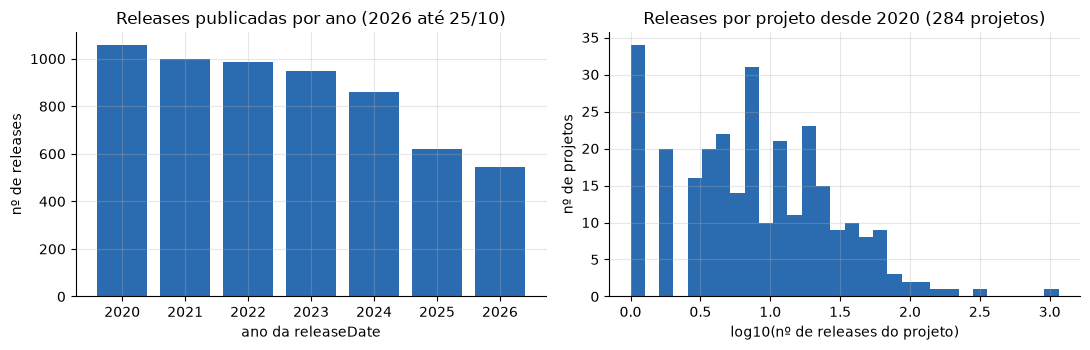

Releases com T0 ≥ 2020: 6,018 em 284 projetos | mediana por projeto: 8 | p90: 40


In [10]:
R = pd.read_csv(BASES / "base_releases.csv", dtype={"version_id": str})
R["release_date"] = ts(R["release_date"])
R20 = R[(R["release_date"] >= SINCE)].copy()
R20["ano"] = R20["release_date"].dt.year
por_ano = R20.groupby("ano").agg(releases=("version_id", "size"), projetos=("project_key", "nunique")).reset_index()
rp = R20.groupby("project_key").size()
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].bar(por_ano["ano"], por_ano["releases"], color="#2b6cb0"); axs[0].set_title("Releases publicadas por ano (2026 até 25/10)")
axs[0].set_xlabel("ano da releaseDate"); axs[0].set_ylabel("nº de releases")
axs[1].hist(np.log10(rp), bins=30, color="#2b6cb0"); axs[1].set_title(f"Releases por projeto desde 2020 ({len(rp)} projetos)")
axs[1].set_xlabel("log10(nº de releases do projeto)"); axs[1].set_ylabel("nº de projetos")
salvar_fig("cap5_releases_ano_projeto")
print(f"Releases com T0 ≥ 2020: {len(R20):,} em {rp.size} projetos | mediana por projeto: {rp.median():.0f} | p90: {rp.quantile(.9):.0f}")

,classe,pares bug×release,%
0,C depois,53816,71.70
1,A antes,20853,27.80
2,B mesmo dia,364,0.50


Bugs distintos vinculados a releases do período: 55,666 | ligados a >1 release: 19.7%


,classificação do projeto,projetos
0,sem releases no periodo,134
1,associacao verificavel (AV>=50%),133
2,dados insuficientes (<30 bugs),103
3,cobertura intermediaria AV (20-50%),31
4,baixa cobertura AV (<20%),17


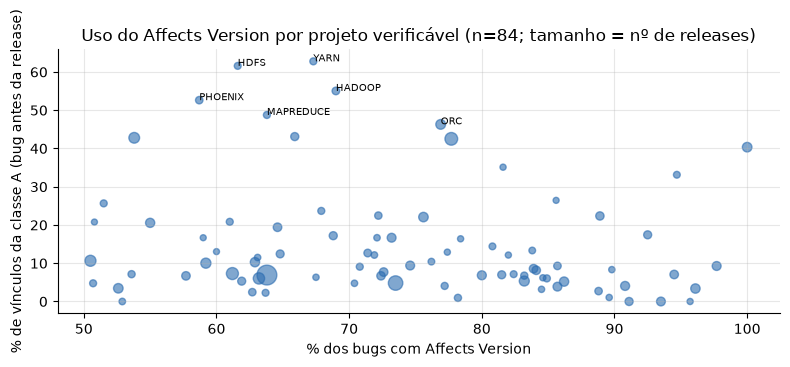

In [11]:
LR = pd.read_csv(BASES / "base_bug_release.csv", dtype={"issue_id": str, "version_id": str})
cls = LR["classe"].value_counts().rename_axis("classe").reset_index(name="pares bug×release")
cls["%"] = (100 * cls["pares bug×release"] / cls["pares bug×release"].sum()).round(1)
display(cls)
multi = LR.groupby("issue_id")["version_id"].nunique()
print(f"Bugs distintos vinculados a releases do período: {LR['issue_id'].nunique():,} | ligados a >1 release: {pct((multi > 1).sum(), len(multi))}%")
reg = pd.read_csv(EVID / "regras_releases_bugs_por_projeto.csv")
display(reg["classificacao_associacao"].value_counts().rename_axis("classificação do projeto").reset_index(name="projetos"))
ver = reg[(reg["classificacao_associacao"] == "associacao verificavel (AV>=50%)") & (reg["releases_T0>=2020"] >= 10)]
salvar_tab(reg, "cap5_regras_releases_bugs_por_projeto")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(ver["affects_version_%"], ver["A_antes_%"], s=np.sqrt(ver["releases_T0>=2020"]) * 6, alpha=.6, color="#2b6cb0")
for _, r_ in ver.nlargest(6, "A_antes_%").iterrows():
    ax.annotate(r_["projeto"], (r_["affects_version_%"], r_["A_antes_%"]), fontsize=7)
ax.set_title(f"Uso do Affects Version por projeto verificável (n={len(ver)}; tamanho = nº de releases)")
ax.set_xlabel("% dos bugs com Affects Version"); ax.set_ylabel("% de vínculos da classe A (bug antes da release)")
salvar_fig("cap5_affects_version_por_projeto")

**Interpretação.**
- **Composição dos vínculos:** a maior parte é da classe C. Uma fração relevante é da classe A, o que indica que alguns projetos (FLINK, HBASE, ORC, SPARK) usam o Affects Version também para a **versão em desenvolvimento**. Esses vínculos não entram como "bugs após a release".
- **Projetos com associação verificável:** só os projetos que preenchem o Affects Version em pelo menos 50% dos bugs sustentam a associação. Os outros não permitem ler "zero bugs" como "release sem defeitos".

### 5.1 Nível de evidência temporal do vínculo

In [12]:
VE = pd.read_csv(BASES / "base_vinculos_evidencia.csv", dtype={"issue_id": str, "version_id": str})
mapa = {"COMPROVADO (inclusao por evento)": "COMPROVADO",
        "RECONSTRUIDO (reverso consistente; premissa: historico completo)": "INFERIDO COM CORROBORAÇÃO",
        "INFERIDO (sem historico corroborante)": "INFERIDO SEM CORROBORAÇÃO", "INDETERMINADO": "INDETERMINADO"}
VE["evidencia"] = VE["nivel"].map(mapa)
ev = VE["evidencia"].value_counts().reindex(list(mapa.values())).rename_axis("nível").reset_index(name="vínculos")
ev["%"] = (100 * ev["vínculos"] / ev["vínculos"].sum()).round(1)
display(ev)
pa = pd.read_csv(EVID / "pendencia_affects_version.csv", low_memory=False)
pa = pa[pa["registro"] == "projeto"]
w = pa[pa["pares_classeC_90d"] > 0]
tot = w["pares_classeC_90d"].sum()
est = pd.DataFrame({"estimativa (janela 90 d, classe C)": ["conservadora (só evento)", "ampliada (+ inferido com corroboração)", "máxima (+ inferido sem corroboração)"],
                    "%": [round((w["conservadora_90d_%"] * w["pares_classeC_90d"]).sum() / tot, 1),
                          round((w["ampliada_90d_%"] * w["pares_classeC_90d"]).sum() / tot, 1),
                          round((w["ampliada_max_90d_%"] * w["pares_classeC_90d"]).sum() / tot, 1)]})
salvar_tab(est, "cap5_evidencia_vinculo_janela90")

,nível,vínculos,%
0,COMPROVADO,27913,15.90
1,INFERIDO COM CORROBORAÇÃO,134133,76.60
2,INFERIDO SEM CORROBORAÇÃO,11124,6.40
3,INDETERMINADO,1993,1.10


,"estimativa (janela 90 d, classe C)",%
0,conservadora (só evento),13.20
1,ampliada (+ inferido com corroboração),95.60
2,máxima (+ inferido sem corroboração),99.00


**Interpretação.**
- **O que é comprovado:** só uma minoria dos vínculos tem a data de inclusão **comprovada** por evento.
- **O que é inferido:** a maioria é **inferida** como presente desde a criação. A reconstrução reversa e a cadeia de status são consistentes, mas isso depende da premissa de histórico completo.

**Limitação conhecida.** Quando uma versão é excluída ou mesclada no Jira, as issues são alteradas **sem evento no histórico**. Isso foi detectado em 969 issues e não é detectável quando a issue não tem outros eventos. Por isso o modelo da seção 9.2 usa a contagem **ampliada**, com a conservadora e a máxima como sensibilidade (decisão pendente D1).

### 5.2 Releases sem bugs vinculados e vínculos fora do recorte

In [13]:
z = R20["classe_180d"].value_counts().rename_axis("classe da release (janela 180 d)").reset_index(name="releases")
display(z)
c = pa[[c_ for c_ in pa.columns if c_[:2] in ("1_", "2_", "3_", "4_", "5_") and c_.endswith(("_vinculos", "_bugs", "fora"))]].sum()
corte = pd.DataFrame({"categoria": ["bug ≥2020 × versão publicada <2020", "bug <2020 × versão publicada ≥2020",
                                    "bug ≥2020 × versão publicada ≥2020", "versão não publicada / sem data / futura"],
                      "vínculos": [c["1_bug>=2020_versao<2020_vinculos"], c["2_bug<2020_versao>=2020_vinculos"],
                                   c["3_bug>=2020_versao>=2020_vinculos"], c["4_versao_sem_data_nao_publicada_ou_futura_vinculos"]],
                      "bugs distintos": [c["1_bug>=2020_versao<2020_bugs"], c["2_bug<2020_versao>=2020_bugs"],
                                         c["3_bug>=2020_versao>=2020_bugs"], c["4_versao_sem_data_nao_publicada_ou_futura_bugs"]]}).astype({"vínculos": int, "bugs distintos": int})
salvar_tab(corte, "cap5_vinculos_fora_do_recorte")

,classe da release (janela 180 d),releases
0,com bugs vinculados,2741
1,zero vinculado (cobertura adequada),1602
2,projeto com baixa cobertura AV (<50%),835
3,dados insuficientes (<30 bugs no projeto),491
4,acompanhamento incompleto,349


,categoria,vínculos,bugs distintos
0,bug ≥2020 × versão publicada <2020,9327,6755
1,bug <2020 × versão publicada ≥2020,2622,2362
2,bug ≥2020 × versão publicada ≥2020,72411,53304
3,versão não publicada / sem data / futura,14968,13545


**Interpretação.**
- **"Zero vinculado":** só é interpretável em projetos com boa cobertura e acompanhamento completo. As outras classes indicam ausência de informação.
- **Vínculos fora do recorte:** bugs recentes ligados a versões anteriores a 2020 ficam fora da análise. Em projetos que mantêm linhas antigas (HIVE, OFBIZ, QPID), isso subestima o volume de defeitos. A perda nas janelas pós-release é pequena (cerca de 5% dos vínculos de 180 d).

### 5.3 Bugs por release: distribuição e associação com características da release

**Método.**
- **População:** releases de projetos verificáveis e **não modulares**, com 180 d de acompanhamento completo.
- **Correlação:** de Spearman, **por projeto** (projetos com pelo menos 20 releases), entre o tamanho da release em T0 e os bugs vinculados em 180 d.
- **Comparação entre tipos de versão:** teste de Kruskal-Wallis, por projeto.

Releases elegíveis: 2,207 em 114 projetos não modulares


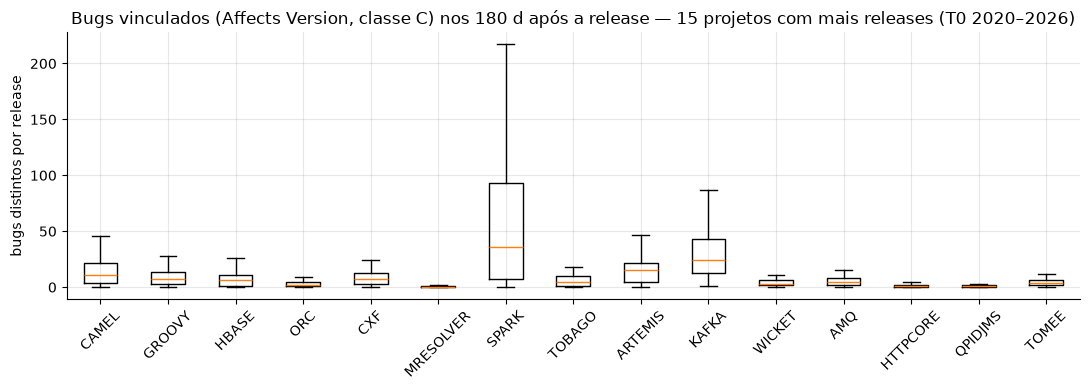

Projetos testados: 35 | rho mediano: 0.37 | rho>0 com p<0,05: 19 | Kruskal-Wallis p<0,05 (tipo de versão): 10 de 26


,projeto,releases,spearman_rho,p_valor,kruskal_tipo_versao_p
2,CAMEL,147,0.69,0.00,0.00
5,GROOVY,106,0.24,0.01,0.01
7,HBASE,92,0.63,0.00,0.00
21,ORC,66,0.50,0.00,0.03
3,CXF,65,0.55,0.00,0.35
16,MRESOLVER,62,0.09,0.47,0.43
25,SPARK,55,0.62,0.00,0.00
30,TOBAGO,54,0.29,0.04,0.01
1,ARTEMIS,53,0.40,0.00,0.07
32,WICKET,49,0.49,0.00,NaN


In [14]:
RM = pd.read_csv(BASES / "modelo_releases.csv", dtype={"version_id": str})
RM["release_date"] = ts(RM["release_date"])
pop = RM[(RM["acompanhamento_180d_completo"] == 1) & (RM["projeto_modular"] == 0)
         & RM["classe_180d"].isin(["zero vinculado (cobertura adequada)", "com bugs vinculados"])]
dist = pop.groupby("project_key")["bugs_180d_ampliado"].agg(releases="size", media="mean", mediana="median",
                                                             var_media=lambda s: s.var() / s.mean() if s.mean() > 0 else np.nan,
                                                             zeros_pct=lambda s: 100 * (s == 0).mean()).reset_index()
print(f"Releases elegíveis: {len(pop):,} em {pop['project_key'].nunique()} projetos não modulares")
top = dist.nlargest(15, "releases")["project_key"]
fig, ax = plt.subplots(figsize=(11, 4))
ax.boxplot([pop.loc[pop["project_key"] == p_, "bugs_180d_ampliado"] for p_ in top], tick_labels=top, showfliers=False)
ax.set_title("Bugs vinculados (Affects Version, classe C) nos 180 d após a release — 15 projetos com mais releases (T0 2020–2026)")
ax.set_ylabel("bugs distintos por release"); plt.xticks(rotation=45)
salvar_fig("cap5_bugs_por_release_projeto")
rows = []
for p_, g in pop.groupby("project_key"):
    if len(g) >= 20 and g["tamanho_t0"].nunique() > 2:
        rho, pv = stats.spearmanr(g["tamanho_t0"], g["bugs_180d_ampliado"])
        tipos = [x["bugs_180d_ampliado"].values for _, x in g.groupby("tipo_versao") if len(x) >= 5]
        kw = stats.kruskal(*tipos).pvalue if len(tipos) >= 2 else np.nan
        rows.append({"projeto": p_, "releases": len(g), "spearman_rho": rho, "p_valor": pv, "kruskal_tipo_versao_p": kw})
assoc = salvar_tab(pd.DataFrame(rows).sort_values("releases", ascending=False).round(4), "cap5_associacao_tamanho_bugs_por_projeto")
print(f"Projetos testados: {len(assoc)} | rho mediano: {assoc['spearman_rho'].median():.2f} | "
      f"rho>0 com p<0,05: {((assoc['spearman_rho'] > 0) & (assoc['p_valor'] < .05)).sum()} | "
      f"Kruskal-Wallis p<0,05 (tipo de versão): {(assoc['kruskal_tipo_versao_p'] < .05).sum()} de {assoc['kruskal_tipo_versao_p'].notna().sum()}")
salvar_tab(dist.round(2), "cap5_bugs_por_release_distribuicao_projeto")
assoc.head(12)

**Interpretação.**
- **Tamanho × bugs:** nesta execução, 19 dos 35 projetos testados mostram correlação positiva e significativa (p < 0,05) entre o tamanho da release em T0 e os bugs vinculados em 180 d, com ρ mediano de 0,37. Nos demais, a associação é fraca ou não significativa, ou seja, o comportamento difere entre projetos.
- **Superdispersão:** a razão variância/média costuma ser bem maior que 1, o que favorece a **Binomial Negativa** em vez da Poisson (seção 9.2).
- **Tipo de versão:** o efeito do tipo de versão (major/minor/patch/pre-release) não é uniforme: o Kruskal-Wallis é significativo em só 10 de 26 projetos.

**Limitações.**
- **Causalidade:** são associações, não causas. Releases maiores também concentram mais atenção e mais registros.
- **Validade do vínculo:** o vínculo depende da prática de preenchimento do Affects Version em cada projeto.
- **Data de publicação:** a `releaseDate` não está comprovada como data real de publicação.

# 6. Tempo de correção (H2 — parte descritiva)

**Pergunta.** Quanto tempo os bugs levam até a primeira resolução, o primeiro fechamento e a primeira correção efetiva?

**Dados.** Base D (bugs criados de 2020 em diante).

**Regras.**
- **B1:** primeiro evento de `resolution` preenchida.
- **B2:** primeira entrada num status de categoria `done` (não "Closed").
- **B3:** primeiro evento `resolution = Fixed`.

Duplicate, Invalid e Won't Fix **não** são correção. Bugs abertos são censurados: nenhuma data final é inventada.

,indicador,bugs datados,% dos bugs,p25 (dias),mediana (dias),p75 (dias),p90 (dias)
0,B1 primeira resolução,88063,76.90,0.91,5.90,36.00,208.09
1,B2 primeiro fechamento,88165,77.00,0.90,5.83,35.02,202.37
2,B3 primeira correção (Fixed),70375,61.40,0.99,5.75,28.39,134.27


Situação de B3:


,status,bugs
0,Fixed datado por evento,70375
1,sem resolucao (aberto/censurado),26718
2,encerrado sem Fixed (nao corrigido),17463


Recuperados pelo histórico (sem resolutiondate, com fechamento datado): 586 | resolutiondate atual ≠ primeira resolução: 3838


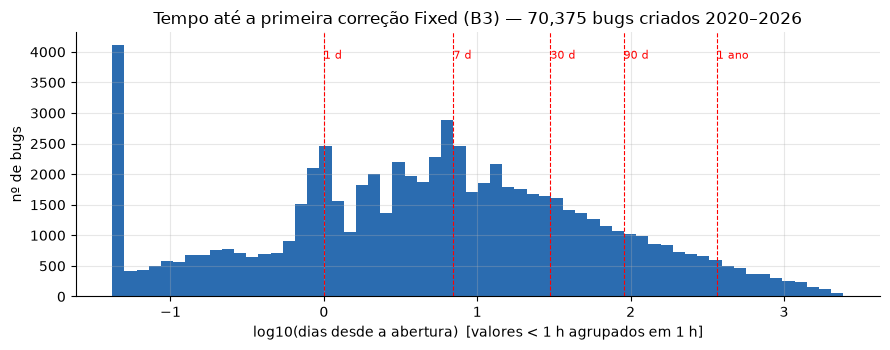

In [15]:
st = pd.DataFrame({
    "indicador": ["B1 primeira resolução", "B2 primeiro fechamento", "B3 primeira correção (Fixed)"],
    "bugs datados": [B["t_b1"].notna().sum(), B["t_b2"].notna().sum(), B["t_b3"].notna().sum()],
})
st["% dos bugs"] = (100 * st["bugs datados"] / len(B)).round(1)
for q, nome in ((.25, "p25 (dias)"), (.5, "mediana (dias)"), (.75, "p75 (dias)"), (.9, "p90 (dias)")):
    st[nome] = [B["d_b1"].quantile(q), B["d_b2"].quantile(q), B["d_b3"].quantile(q)]
display(salvar_tab(st.round(2), "cap6_indicadores_tempo"))
print("Situação de B3:"); display(B["b3_status"].value_counts().rename_axis("status").reset_index(name="bugs"))
print(f"Recuperados pelo histórico (sem resolutiondate, com fechamento datado): {int(B['recup_hist'].sum())} | "
      f"resolutiondate atual ≠ primeira resolução: {int(B['rd_differs_b1'].sum())}")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(np.log10(B["d_b3"].dropna().clip(lower=1 / 24)), bins=60, color="#2b6cb0")
for d_, lab in ((1, "1 d"), (7, "7 d"), (30, "30 d"), (90, "90 d"), (365, "1 ano")):
    ax.axvline(np.log10(d_), color="red", lw=.8, ls="--"); ax.text(np.log10(d_), ax.get_ylim()[1] * .9, lab, fontsize=8, color="red")
ax.set_title(f"Tempo até a primeira correção Fixed (B3) — {B['t_b3'].notna().sum():,} bugs criados 2020–2026")
ax.set_xlabel("log10(dias desde a abertura)  [valores < 1 h agrupados em 1 h]"); ax.set_ylabel("nº de bugs")
salvar_fig("cap6_distribuicao_b3")

,30,90
situação no horizonte,,
acompanhamento incompleto,3114,5957
corrigido (Fixed) ate 30d,51760,0
corrigido (Fixed) ate 90d,0,57792
nao corrigido em 30d,59682,0
nao corrigido em 90d,0,50807


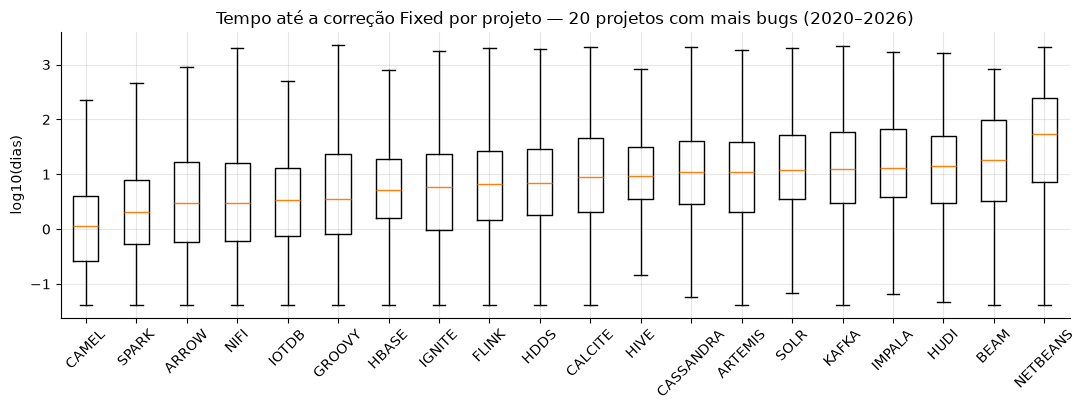

,projeto,bugs>=2020,mediana_dias_B3,fixed_ate_90d_%,encerrado_sem_fixed_%,fluxo_Resolved->Closed_%
0,FLINK,9588,6.64,47.58,22.01,2.21
1,SPARK,6394,2.05,56.61,13.59,38.82
2,IGNITE,5443,5.93,61.98,11.68,1.49
3,KAFKA,3939,12.62,45.05,12.57,1.98
4,CAMEL,3644,1.13,79.59,13.42,0.69
5,HDDS,3642,7.03,59.73,18.12,0.99
6,ARROW,3570,3.05,59.05,17.65,2.89
7,CASSANDRA,3215,10.82,53.69,14.46,0.00
8,NIFI,2969,3.05,58.91,23.48,1.04
9,HIVE,2948,9.30,50.53,9.33,40.57


In [16]:
hz = pd.DataFrame({h: B[f"h{h}_b3"].value_counts() for h in (30, 90)}).fillna(0).astype(int)
hz.index.name = "situação no horizonte"
display(hz)
pr = pd.read_csv(EVID / "regras_tempo_correcao_por_projeto.csv")
pr = pr[pr["bugs>=2020"] >= 200].sort_values("bugs>=2020", ascending=False)
salvar_tab(pr, "cap6_tempo_correcao_por_projeto")
g = B[B["project"].isin(pr["projeto"].head(20))]
ordem = g.groupby("project")["d_b3"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.boxplot([np.log10(g.loc[g["project"] == p_, "d_b3"].dropna().clip(lower=1 / 24)) for p_ in ordem], tick_labels=ordem, showfliers=False)
ax.set_title("Tempo até a correção Fixed por projeto — 20 projetos com mais bugs (2020–2026)")
ax.set_ylabel("log10(dias)"); plt.xticks(rotation=45)
salvar_fig("cap6_b3_por_projeto")
pr[["projeto", "bugs>=2020", "mediana_dias_B3", "fixed_ate_90d_%", "encerrado_sem_fixed_%", "fluxo_Resolved->Closed_%"]].head(12)

**Interpretação.**
- **B1 × B2:** são praticamente equivalentes, porque a resolução é registrada na mesma transição que leva ao primeiro estado terminal. Usar "Closed" inflaria os tempos nos workflows de dois estágios.
- **B3:** é a medida de **correção efetiva** e exclui os encerramentos sem correção, que chegam a cerca de 28% dos bugs em alguns projetos (p90).
- **Assimetria:** a distribuição é muito assimétrica; uma parte grande dos bugs é corrigida em menos de uma semana e uma cauda longa ultrapassa um ano.
- **Diferenças entre projetos:** as medianas variam bastante, o que justifica o efeito de projeto na modelagem.

**Possibilidade de previsão por faixas.** No horizonte fixo de 90 dias, todo bug com acompanhamento completo recebe uma faixa (≤ 7 d, 8–30 d, 31–90 d, > 90 d ou não Fixed) sem inventar datas. Isso viabiliza a classificação da seção 9.1.

**Limitações.**
- **Censura:** sem análise de sobrevivência, que não foi encontrada nos materiais do MBA, a censura é tratada só pelo horizonte fixo.
- **Tempo × esforço:** tempo decorrido não é esforço.

# 7. Retrabalho: reaberturas e estabilidade (exploratório)

**Pergunta.** Com que frequência e em quanto tempo bugs resolvidos são reabertos? As resoluções são estáveis?

**Regra.**
- **Reabertura:** transição de um status de categoria `done` para `new` ou `indeterminate`; a categoria vem do Jira, não do nome. Resolved → Closed **não** é reabertura.
- **Papel da Resolution:** a limpeza da Resolution é corroboração, não requisito.
- **Reaberturas rápidas (≤ 5 min):** são sinalizadas, nunca excluídas.

,indicador,valor
0,bugs com fechamento datado,"88,165.00"
1,bugs reabertos,"4,555.00"
2,% dos fechados,5.20
3,reabertos >1 vez,391.00
4,eventos de reabertura,"5,022.00"
5,mediana de duração adicional após reabrir (dias),12.50


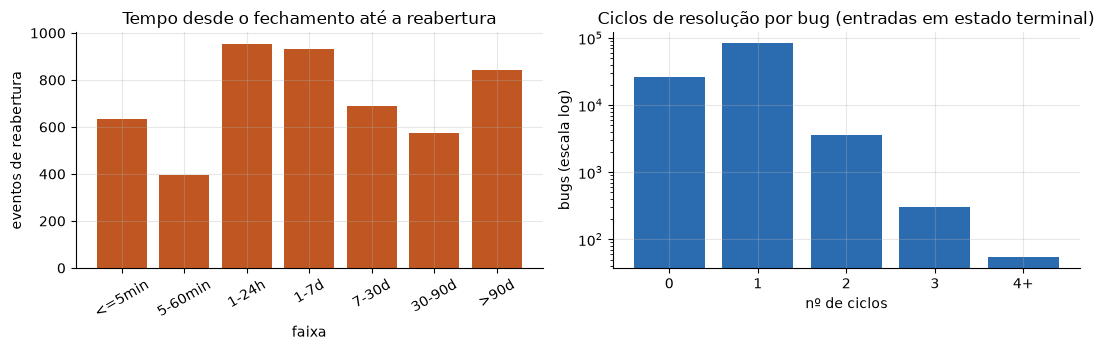

In [17]:
RE = pd.read_csv(BASES / "base_reaberturas.csv", dtype={"issue_id": str})
fechados = B["t_b2"].notna() | (B["n_reab"] > 0)
freq = pd.DataFrame({"indicador": ["bugs com fechamento datado", "bugs reabertos", "% dos fechados", "reabertos >1 vez",
                                   "eventos de reabertura", "mediana de duração adicional após reabrir (dias)"],
                     "valor": [int(fechados.sum()), int((B["n_reab"] > 0).sum()), pct((B["n_reab"] > 0).sum(), fechados.sum()),
                               int((B["n_reab"] > 1).sum()), len(RE), round(B["dur_adic_dias"].median(), 1)]})
display(salvar_tab(freq, "cap7_frequencia_reabertura"))
fx = RE["faixa"].value_counts().reindex(["<=5min", "5-60min", "1-24h", "1-7d", "7-30d", "30-90d", ">90d"])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
axs[0].bar(fx.index, fx.values, color="#c05621"); axs[0].set_title("Tempo desde o fechamento até a reabertura")
axs[0].set_xlabel("faixa"); axs[0].set_ylabel("eventos de reabertura"); axs[0].tick_params(axis="x", rotation=30)
cc = B["n_ciclos"].clip(upper=4).value_counts().sort_index()
axs[1].bar(cc.index.astype(str).str.replace("4", "4+"), cc.values, color="#2b6cb0"); axs[1].set_yscale("log")
axs[1].set_title("Ciclos de resolução por bug (entradas em estado terminal)"); axs[1].set_xlabel("nº de ciclos"); axs[1].set_ylabel("bugs (escala log)")
salvar_fig("cap7_reabertura_tempo_ciclos")

,base,janela (dias),estáveis,reabertas,acompanhamento insuficiente,% estáveis (elegíveis)
0,1º fechamento,30,82860,3268,2037,96.20
1,1º fechamento,90,80168,3793,4204,95.50
2,1ª correção Fixed,30,66216,2228,1931,96.70
3,1ª correção Fixed,90,63827,2626,3922,96.00


,reaberturas ≤ 5 min: o que acontece em seguida,eventos
0,re-encerrado <=1h com Resolution diferente (in...,209
1,re-encerrado >1h (indicio de novo ciclo operac...,203
2,re-encerrado <=1h sem outra alteracao (indeter...,90
3,re-encerrado <=1h com outros campos alterados ...,70
4,sem novo fechamento (permanece aberto),64


Concordância status × Resolution (bugs): ambos=4163, só status=392, só Resolution=1, nenhum=110000


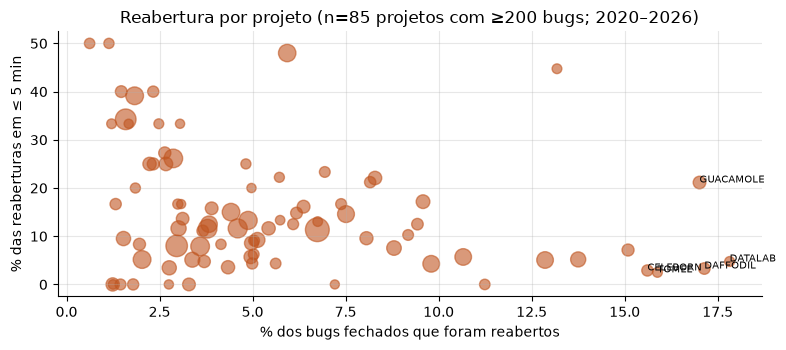

In [18]:
estab = []
for base_, nome in (("fechamento", "1º fechamento"), ("fixed", "1ª correção Fixed")):
    for w_ in (30, 90):
        s_ = B[f"est_{base_}_{w_}"].value_counts()
        el = s_.get("estavel", 0) + s_.get("reaberta na janela", 0)
        estab.append({"base": nome, "janela (dias)": w_, "estáveis": s_.get("estavel", 0), "reabertas": s_.get("reaberta na janela", 0),
                      "acompanhamento insuficiente": s_.get("acompanhamento insuficiente", 0), "% estáveis (elegíveis)": pct(s_.get("estavel", 0), el)})
display(salvar_tab(pd.DataFrame(estab), "cap7_estabilidade"))
rq = pd.read_csv(BASES / "base_reaberturas_rapidas.csv")
display(rq["classe"].value_counts().rename_axis("reaberturas ≤ 5 min: o que acontece em seguida").reset_index(name="eventos"))
cc_ = pd.read_csv(EVID / "pendencia_reaberturas_concordancia.csv")
gl = cc_[cc_["escopo"] == "GLOBAL"].iloc[0]
print(f"Concordância status × Resolution (bugs): ambos={int(gl['A_status_e_resolution'])}, só status={int(gl['B_somente_status'])}, "
      f"só Resolution={int(gl['C_somente_resolution'])}, nenhum={int(gl['D_nenhum'])}")
rp_ = pd.read_csv(EVID / "regras_reaberturas_por_projeto.csv")
rp_ = rp_[rp_["bugs>=2020"] >= 200]
salvar_tab(rp_, "cap7_reaberturas_por_projeto")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(rp_["reabertos_%_dos_fechados"], rp_["reabertura_<=5min_%"], s=np.sqrt(rp_["bugs>=2020"]) * 3, alpha=.6, color="#c05621")
for _, r_ in rp_.nlargest(5, "reabertos_%_dos_fechados").iterrows():
    ax.annotate(r_["projeto"], (r_["reabertos_%_dos_fechados"], r_["reabertura_<=5min_%"]), fontsize=7)
ax.set_title(f"Reabertura por projeto (n={len(rp_)} projetos com ≥200 bugs; 2020–2026)")
ax.set_xlabel("% dos bugs fechados que foram reabertos"); ax.set_ylabel("% das reaberturas em ≤ 5 min")
salvar_fig("cap7_reabertura_por_projeto")

**Interpretação.**
- **Frequência:** a reabertura é um **evento raro**, e a estabilidade em 30 e 90 dias é alta.
- **Variação entre projetos:** a taxa de reabertura e a fração de reaberturas imediatas variam bastante entre projetos.
- **Reaberturas rápidas:** são heterogêneas. Cerca de um terço tem re-encerramento em até 1 h com outra Resolution (indício de correção administrativa), e outro terço tem novo ciclo de trabalho.
- **Concordância:** os critérios por status e por Resolution concordam em quase todos os bugs. As divergências se explicam por workflows que não limpam a Resolution ou que fecham sem ela.

**Limitações.** Os projetos só são comparáveis dentro de workflows compatíveis. Nenhum projeto é comparado pela métrica de Resolution quando fecha sem preenchê-la (HUDI, CELEBORN).

# 8. Governança operacional: composição das demandas (exploratório)

**Pergunta.** Como se distribuem correções, evolução e outras demandas, por projeto e ao longo do tempo?

**Tratamento.**
- **Classes por tipo de issue (proxy):** Bug = correção; Improvement, New Feature, Wish, Story e Epic = evolução; Task, Sub-task e outros = indefinido. A classificação é **declarada como proxy**: nem todo Bug é sustentação, nem toda Improvement é evolução.
- **Esforço:** horas de worklog **não** são usadas como esforço.
- **Pessoas:** não há rankings individuais.

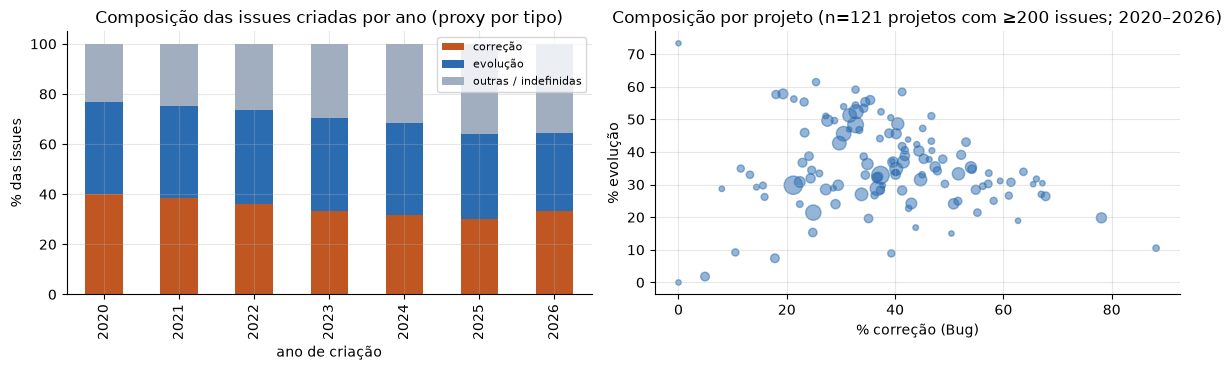

Responsável atual registrado (mediana por projeto, ≥200 issues): 72.6%


In [19]:
TI = pd.read_csv(EVID / "obj4_tipos_issue_por_ano.csv")
classe = {"correcao (proxy)": "correção", "evolucao (proxy)": "evolução"}
TI["classe"] = TI["classe_proxy"].map(classe).fillna("outras / indefinidas")
F = TI.groupby(["cyear", "classe"])["issues"].sum().unstack(fill_value=0)
F = F[F.index <= 2026]; F.index = F.index.astype(int)
salvar_tab(F.reset_index(), "base_F_demandas_por_ano_classe")
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
(F.div(F.sum(axis=1), axis=0) * 100).plot(kind="bar", stacked=True, ax=axs[0], color=["#c05621", "#2b6cb0", "#a0aec0"])
axs[0].set_title("Composição das issues criadas por ano (proxy por tipo)"); axs[0].set_xlabel("ano de criação"); axs[0].set_ylabel("% das issues")
axs[0].legend(fontsize=8)
Pd = P[P["issues_criadas>=2020"] >= 200]
axs[1].scatter(Pd["share_correcao_%"], Pd["share_evolucao_%"], s=np.sqrt(Pd["issues_criadas>=2020"]), alpha=.5, color="#2b6cb0")
axs[1].set_title(f"Composição por projeto (n={len(Pd)} projetos com ≥200 issues; 2020–2026)")
axs[1].set_xlabel("% correção (Bug)"); axs[1].set_ylabel("% evolução")
salvar_fig("cap8_composicao_demandas")
print(f"Responsável atual registrado (mediana por projeto, ≥200 issues): {Pd['assignee_atual_%'].median():.1f}%")

In [20]:
WL = pd.read_csv(EVID / "obj4_worklogs_por_ano_origem.csv")
wl = WL.groupby("origem")[["worklogs", "horas"]].sum()
wl["% worklogs"] = (100 * wl["worklogs"] / wl["worklogs"].sum()).round(2)
wl["% horas"] = (100 * wl["horas"] / wl["horas"].sum()).round(1)
salvar_tab(wl.reset_index(), "cap8_worklogs_origem")
wl

,worklogs,horas,% worklogs,% horas
origem,,,,
conta automatica,842633,"140,438.90",99.84,89.40
demais contas,1342,"16,595.10",0.16,10.60


**Interpretação.**
- **Composição:** correção e evolução respondem por parcelas comparáveis das demandas, com grande variação entre projetos. Há projetos dominados por correções e outros por evolução.
- **Atribuição:** o responsável registrado cobre só uma parte das issues e não representa todos os envolvidos.
- **Worklogs:** quase todos vêm da conta automática da integração com o GitHub, com registros padronizados de 10 minutos. As **horas não medem esforço**, e o esforço real não é observável nesta base.

**Limitações.**
- **Proxy:** a classificação por tipo é aproximada.
- **Tempo × esforço:** tempo decorrido e volume de demandas não equivalem a esforço.
- **Produtividade:** não há inferência de produtividade individual.

# 9. Modelagem preditiva

Os dois problemas centrais são modelados com o mesmo protocolo:
- **Instante de previsão (T0):** só variáveis **disponíveis em T0**, reconstruídas pelo changelog (`src/preparacao/07_bases_modelagem.py`).
- **Divisão cronológica:** treino com T0 em 2020–2023; teste com T0 a partir de 2024 e horizonte completamente observado.
- **Modelos:** um **baseline** por projeto e **um modelo ensinado no MBA** (ver `docs/metodologia.md`), com **efeito fixo de projeto** (dummies) como segunda camada.
- **Avaliação:** os resultados são reportados no total e **por projeto**.

Árvores, Random Forest e Boosting também foram ensinados, mas não são usados aqui, para não multiplicar modelos sem justificativa. Ficam como possibilidade futura.

## 9.1 H2 — Faixa de tempo até a primeira correção (classificação multinomial)

| Elemento | Definição |
|---|---|
| Unidade / T0 | bug, na sua criação |
| Alvo | faixa no horizonte de 90 d: `<=7d`, `8-30d`, `31-90d`, `>90d ou nao Fixed` |
| Features (T0) | prioridade na abertura (reconstruída), responsável na abertura, Affects Version na criação, nº de componentes na criação, bugs do projeto nos 30 d anteriores, backlog aberto do projeto, projeto (efeito fixo) |
| População | projetos com volume para modelo individual ou agrupado (`projetos_viabilidade_modelos.csv`), com treino e teste |
| Treino / teste | criação em 2020–2023 / de 2024-01-01 a 2025-07-27 (90 d observáveis) |
| Baseline | classe mais frequente do projeto no treino |
| Modelo | regressão logística multinomial (ensinada; `LogisticRegression`, padronização + one-hot) |
| Métricas | acurácia, acurácia balanceada, F1 macro; matriz de confusão |

In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix

MB = pd.read_csv(BASES / "modelo_bugs_faixa.csv", dtype={"issue_id": str})
VB = pd.read_csv(EVID / "projetos_viabilidade_modelos.csv")
v2 = VB[VB["objetivo"].astype(str) == "2"]
ind2 = set(v2.loc[v2["classificacao"] == "MODELO INDIVIDUAL VIAVEL", "projeto"])
agr2 = set(v2.loc[v2["classificacao"].str.startswith(("MODELO", "AGRUPADO")), "projeto"])
D = MB[MB["project"].isin(agr2) & MB["split"].isin(["treino", "teste"])].copy()
D = D[D["project"].isin(set(D.loc[D["split"] == "treino", "project"]) & set(D.loc[D["split"] == "teste", "project"]))]
freq_p = D.loc[D["split"] == "treino", "prioridade_t0"].value_counts()
D["prioridade_t0"] = D["prioridade_t0"].where(D["prioridade_t0"].isin(freq_p[freq_p >= 200].index), "Outra/rara").fillna("Outra/rara")
for c_ in ("componentes_na_criacao", "bugs_projeto_30d_anteriores", "backlog_aberto_projeto_t0"):
    D["log_" + c_] = np.log1p(D[c_].clip(lower=0))
NUM = ["responsavel_na_abertura", "affects_version_na_criacao", "log_componentes_na_criacao",
       "log_bugs_projeto_30d_anteriores", "log_backlog_aberto_projeto_t0"]
CAT = ["prioridade_t0", "project"]
CLASSES = ["<=7d", "8-30d", "31-90d", ">90d ou nao Fixed"]
tr, te = D[D["split"] == "treino"], D[D["split"] == "teste"]
print(f"Projetos: {D['project'].nunique()} | treino: {len(tr):,} bugs | teste: {len(te):,} bugs")
display(pd.crosstab(D["split"], D["faixa_90d"], normalize="index").reindex(columns=CLASSES).mul(100).round(1))

def pipe(cat):
    return Pipeline([("prep", ColumnTransformer([("num", StandardScaler(), NUM),
                                                 ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])),
                     ("clf", LogisticRegression(max_iter=3000, C=1.0))])

modelo = pipe(CAT).fit(tr[NUM + CAT], tr["faixa_90d"])
te = te.assign(pred_modelo=modelo.predict(te[NUM + CAT]))
maj = tr.groupby("project")["faixa_90d"].agg(lambda s: s.value_counts().index[0])
te = te.assign(pred_baseline=te["project"].map(maj))

def metr(y, p):
    return {"acurácia": accuracy_score(y, p), "acurácia balanceada": balanced_accuracy_score(y, p), "F1 macro": f1_score(y, p, average="macro")}

res_h2 = pd.DataFrame({"baseline (classe majoritária do projeto)": metr(te["faixa_90d"], te["pred_baseline"]),
                       "logística multinomial + efeito de projeto": metr(te["faixa_90d"], te["pred_modelo"])}).T.round(3)
salvar_tab(res_h2.reset_index().rename(columns={"index": "modelo"}), "cap9_h2_metricas_teste")
res_h2

Projetos: 91 | treino: 64,520 bugs | teste: 25,704 bugs


faixa_90d,<=7d,8-30d,31-90d,>90d ou nao Fixed
split,,,,
teste,36.50,14.20,7.60,41.70
treino,32.90,13.50,7.10,46.50


,acurácia,acurácia balanceada,F1 macro
baseline (classe majoritária do projeto),0.46,0.28,0.23
logística multinomial + efeito de projeto,0.53,0.34,0.29


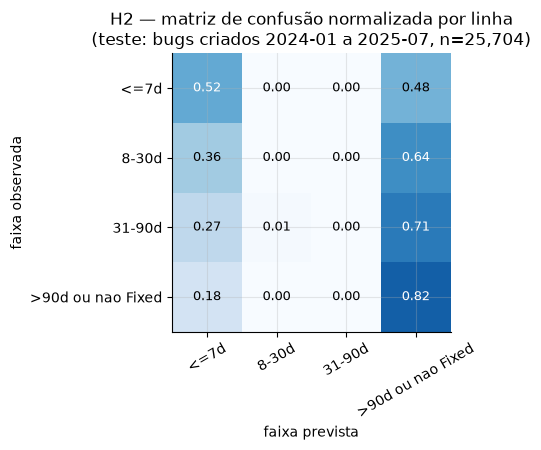

Projetos em que o agrupado supera o baseline (F1 macro): 72 de 91
Projetos com modelo individual (22): individual > baseline em 21; individual > agrupado em 6


,projeto,bugs_teste,F1 baseline,F1 agrupado,F1 individual
32,IGNITE,2373,0.12,0.31,0.31
19,FLINK,2200,0.18,0.31,0.31
70,SPARK,1808,0.14,0.16,0.21
40,KAFKA,1377,0.16,0.26,0.27
33,IMPALA,1114,0.17,0.28,0.25
10,CASSANDRA,1103,0.16,0.30,0.30
9,CAMEL,1083,0.21,0.21,0.23
27,HDDS,1025,0.15,0.29,0.29
50,NIFI,986,0.12,0.35,0.35
8,CALCITE,826,0.13,0.18,0.13


In [22]:
cm = confusion_matrix(te["faixa_90d"], te["pred_modelo"], labels=CLASSES, normalize="true")
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES, rotation=30); ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", color="white" if cm[i, j] > .5 else "black", fontsize=9)
ax.set_xlabel("faixa prevista"); ax.set_ylabel("faixa observada")
ax.set_title(f"H2 — matriz de confusão normalizada por linha\n(teste: bugs criados 2024-01 a 2025-07, n={len(te):,})")
salvar_fig("cap9_h2_matriz_confusao")
# desempenho por projeto e modelos individuais nos projetos elegíveis
linhas = []
for p_, g in te.groupby("project"):
    row = {"projeto": p_, "bugs_teste": len(g), "F1 baseline": f1_score(g["faixa_90d"], g["pred_baseline"], average="macro"),
           "F1 agrupado": f1_score(g["faixa_90d"], g["pred_modelo"], average="macro"), "F1 individual": np.nan}
    if p_ in ind2:
        trp = tr[tr["project"] == p_]
        mi = pipe(["prioridade_t0"]).fit(trp[NUM + ["prioridade_t0"]], trp["faixa_90d"])
        row["F1 individual"] = f1_score(g["faixa_90d"], mi.predict(g[NUM + ["prioridade_t0"]]), average="macro")
    linhas.append(row)
pp = salvar_tab(pd.DataFrame(linhas).round(3).sort_values("bugs_teste", ascending=False), "cap9_h2_metricas_por_projeto")
ii = pp[pp["F1 individual"].notna()]
print(f"Projetos em que o agrupado supera o baseline (F1 macro): {(pp['F1 agrupado'] > pp['F1 baseline']).sum()} de {len(pp)}")
print(f"Projetos com modelo individual ({len(ii)}): individual > baseline em {(ii['F1 individual'] > ii['F1 baseline']).sum()}; "
      f"individual > agrupado em {(ii['F1 individual'] > ii['F1 agrupado']).sum()}")
ii.head(22)

In [23]:
# interpretação: coeficientes padronizados das variáveis numéricas por classe (referência implícita: média das classes)
coef = pd.DataFrame(modelo.named_steps["clf"].coef_[:, :len(NUM)], index=modelo.named_steps["clf"].classes_, columns=NUM).T
salvar_tab(coef.round(3).reset_index().rename(columns={"index": "variável (padronizada)"}), "cap9_h2_coeficientes_numericos")
coef.round(3)

,31-90d,8-30d,<=7d,>90d ou nao Fixed
responsavel_na_abertura,-0.06,0.10,0.37,-0.42
affects_version_na_criacao,0.00,-0.03,-0.08,0.11
log_componentes_na_criacao,0.01,0.01,-0.01,-0.01
log_bugs_projeto_30d_anteriores,-0.04,0.03,0.05,-0.04
log_backlog_aberto_projeto_t0,0.02,0.01,-0.05,0.03


## 9.2 H1 — Bugs vinculados à release nos 180 dias seguintes (Binomial Negativa)

| Elemento | Definição |
|---|---|
| Unidade / T0 | release, na `releaseDate` |
| Alvo | nº de bugs distintos com Affects Version = release, criados em (T0, T0+180 d]; nível de evidência **ampliado** (sensibilidade: conservador e máximo) |
| Features (T0) | log(tamanho da release em T0), proporção de bugs e de evolução na composição em T0, log(dias desde a release anterior), releases do projeto nos 90 d anteriores, tipo de versão, projeto (efeito fixo) |
| População | releases de projetos verificáveis, **não modulares**, com acompanhamento de 180 d completo e ≥ 10 releases no treino |
| Treino / teste | T0 em 2020–2023 / de 2024-01-01 a 2026-04-28 |
| Baseline | média de bugs por release do projeto no treino |
| Modelo | regressão Binomial Negativa (ensinada; `statsmodels`), justificada pela superdispersão (Cap. 5) |
| Métricas | MAE, RMSE e correlação de Spearman entre previsto e observado (ordenação de risco) |

In [24]:
import statsmodels.formula.api as smf
X = pop.copy()
X["log_tamanho"] = np.log1p(X["tamanho_t0"])
X["prop_bugs"] = np.where(X["tamanho_t0"] > 0, X["bugs_na_release_t0"] / X["tamanho_t0"].replace(0, np.nan), 0)
X["prop_evol"] = np.where(X["tamanho_t0"] > 0, X["evolucao_na_release_t0"] / X["tamanho_t0"].replace(0, np.nan), 0)
X["log_dias_anterior"] = np.log1p(X["dias_desde_release_anterior"].fillna(X["dias_desde_release_anterior"].median()).clip(lower=0))
ntr = X[X["split"] == "treino"].groupby("project_key").size()
X = X[X["project_key"].isin(ntr[ntr >= 10].index) & X["split"].isin(["treino", "teste"])]
trr, ter = X[X["split"] == "treino"], X[X["split"] == "teste"]
ter = ter[ter["project_key"].isin(trr["project_key"].unique())]
print(f"Projetos: {trr['project_key'].nunique()} | releases treino: {len(trr):,} | teste: {len(ter):,}")
FORM = "{y} ~ log_tamanho + prop_bugs + prop_evol + log_dias_anterior + releases_90d_anteriores + C(tipo_versao) + C(project_key)"
nb = smf.negativebinomial(FORM.format(y="bugs_180d_ampliado"), data=trr).fit(maxiter=500, disp=0)
ter = ter.assign(pred_nb=nb.predict(ter), pred_base=ter["project_key"].map(trr.groupby("project_key")["bugs_180d_ampliado"].mean()))
def mreg(y, p):
    return {"MAE": np.mean(np.abs(y - p)), "RMSE": np.sqrt(np.mean((y - p) ** 2)), "Spearman (previsto × observado)": stats.spearmanr(p, y)[0]}
res_h1 = pd.DataFrame({"baseline (média do projeto no treino)": mreg(ter["bugs_180d_ampliado"], ter["pred_base"]),
                       "Binomial Negativa + efeito de projeto": mreg(ter["bugs_180d_ampliado"], ter["pred_nb"])}).T.round(3)
salvar_tab(res_h1.reset_index().rename(columns={"index": "modelo"}), "cap9_h1_metricas_teste")
print(f"alpha (superdispersão) estimado: {nb.params['alpha']:.3f}")
res_h1

Projetos: 49 | releases treino: 1,198 | teste: 588


alpha (superdispersão) estimado: 0.554


,MAE,RMSE,Spearman (previsto × observado)
baseline (média do projeto no treino),9.28,20.07,0.49
Binomial Negativa + efeito de projeto,6.63,13.04,0.59


In [25]:
termos = [t for t in nb.params.index if not t.startswith("C(project_key)") and t not in ("Intercept", "alpha")]
ci = nb.conf_int().loc[termos]
irr = pd.DataFrame({"IRR (razão de taxas)": np.exp(nb.params[termos]), "IC95% inf": np.exp(ci[0]), "IC95% sup": np.exp(ci[1]),
                    "p-valor": nb.pvalues[termos]}).round(3)
salvar_tab(irr.reset_index().rename(columns={"index": "termo"}), "cap9_h1_irr")
display(irr)
sens = []
for alvo in ("bugs_180d_conservador", "bugs_180d_ampliado", "bugs_180d_maximo"):
    f = smf.negativebinomial(FORM.format(y=alvo), data=trr).fit(maxiter=500, disp=0)
    p_ = f.predict(ter)
    sens.append({"nível de evidência do alvo": alvo.replace("bugs_180d_", ""), "média observada (teste)": ter[alvo].mean(),
                 "IRR log_tamanho": np.exp(f.params["log_tamanho"]), "p log_tamanho": f.pvalues["log_tamanho"],
                 "MAE modelo": np.mean(np.abs(ter[alvo] - p_)),
                 "MAE baseline": np.mean(np.abs(ter[alvo] - ter["project_key"].map(trr.groupby("project_key")[alvo].mean())))})
salvar_tab(pd.DataFrame(sens).round(3), "cap9_h1_sensibilidade_evidencia")

,IRR (razão de taxas),IC95% inf,IC95% sup,p-valor
C(tipo_versao)[T.minor],0.85,0.62,1.16,0.31
C(tipo_versao)[T.outro],0.71,0.15,3.38,0.67
C(tipo_versao)[T.patch],1.06,0.78,1.45,0.70
C(tipo_versao)[T.pre-release],0.73,0.52,1.02,0.07
log_tamanho,1.40,1.32,1.49,0.00
prop_bugs,1.40,1.07,1.84,0.01
prop_evol,1.74,1.21,2.52,0.00
log_dias_anterior,1.00,0.96,1.04,0.95
releases_90d_anteriores,1.00,0.96,1.04,0.88


,nível de evidência do alvo,média observada (teste),IRR log_tamanho,p log_tamanho,MAE modelo,MAE baseline
0,conservador,1.27,1.45,0.00,1.33,1.62
1,ampliado,8.20,1.40,0.00,6.63,9.28
2,maximo,8.42,1.39,0.00,6.90,9.58


Projetos em que a Binomial Negativa tem MAE menor que o baseline: 32 de 43


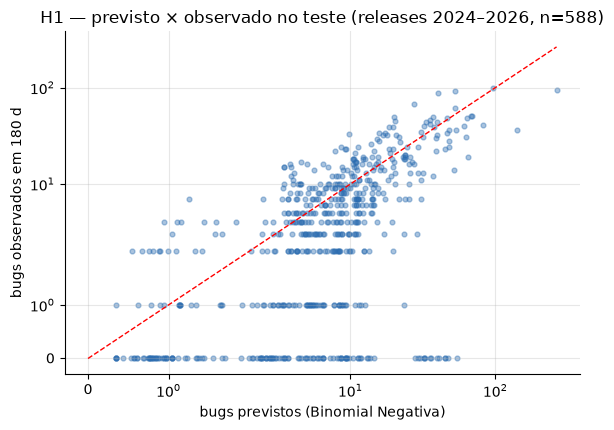

,projeto,releases_teste,MAE baseline,MAE Binomial Negativa
2,CAMEL,57,10.51,8.01
6,GROOVY,36,8.35,6.51
31,SPARK,29,76.53,38.59
26,ORC,28,2.64,2.27
3,CXF,27,5.95,5.13
1,ARTEMIS,25,12.39,10.28
8,HBASE,24,6.94,5.33
37,TOBAGO,24,5.35,5.23
21,MRESOLVER,22,1.04,0.94
0,AMQ,20,4.24,3.62


In [26]:
lin = []
for p_, g in ter.groupby("project_key"):
    lin.append({"projeto": p_, "releases_teste": len(g), "MAE baseline": np.mean(np.abs(g["bugs_180d_ampliado"] - g["pred_base"])),
                "MAE Binomial Negativa": np.mean(np.abs(g["bugs_180d_ampliado"] - g["pred_nb"]))})
pp1 = salvar_tab(pd.DataFrame(lin).round(2).sort_values("releases_teste", ascending=False), "cap9_h1_metricas_por_projeto")
print(f"Projetos em que a Binomial Negativa tem MAE menor que o baseline: {(pp1['MAE Binomial Negativa'] < pp1['MAE baseline']).sum()} de {len(pp1)}")
fig, ax = plt.subplots(figsize=(6, 4.4))
mx = max(ter["bugs_180d_ampliado"].max(), ter["pred_nb"].max())
ax.scatter(ter["pred_nb"], ter["bugs_180d_ampliado"], alpha=.4, s=12, color="#2b6cb0")
ax.plot([0, mx], [0, mx], "r--", lw=1)
ax.set_xscale("symlog"); ax.set_yscale("symlog")
ax.set_xlabel("bugs previstos (Binomial Negativa)"); ax.set_ylabel("bugs observados em 180 d")
ax.set_title(f"H1 — previsto × observado no teste (releases 2024–2026, n={len(ter)})")
salvar_fig("cap9_h1_previsto_observado")
pp1.head(15)

## 9.3 Reabertura: possibilidade futura (não modelada)

A previsão de reabertura no momento da resolução é **viável com restrições**: com os critérios atuais, só 3 projetos (FLINK, HBASE, ARTEMIS) têm eventos suficientes para modelo individual, e 33 entram apenas num modelo agrupado. Como é um evento raro (~5%), ela exigiria técnicas de balanceamento que foram apenas mencionadas nos materiais do MBA. **Não foi executada nesta versão**, e nenhum resultado é apresentado.

# 10. Conclusões e limitações

Os números citados são **os desta execução** (snapshot de 25/10/2026) e constam das tabelas em `resultados/tabelas/`.

## 10.1 Principais achados

| Frente | Resultado observado |
|---|---|
| Coleta | 561.369 issues de 650 projetos; 50/50 janelas reconciliadas; 0 duplicatas; changelog, comentários e worklogs completos |
| Releases × bugs | 6.018 releases desde 2020 em 284 projetos. Dos vínculos por Affects Version, 71,7% são da classe C (bug após a release) e 27,8% da classe A (bug antes da release, uso do campo para a linha em desenvolvimento). 133 projetos têm associação verificável. A data de inclusão do vínculo é **comprovada** em 15,9% dos casos e **inferida com corroboração** em 76,6%. |
| Tempo de correção | 114.556 bugs desde 2020. A primeira correção Fixed está datada em 61,4%, com mediana de 5,75 dias (p90 = 134 dias). 17.463 bugs foram encerrados sem correção e 26.718 continuam abertos (censurados). 586 datas foram recuperadas pelo histórico. |
| Retrabalho | 4.555 bugs reabertos (5,2% dos fechados), 391 mais de uma vez. A estabilidade em 90 d é de 95,5% após o primeiro fechamento e de 96,0% após o primeiro Fixed. 12,7% das reaberturas ocorrem em até 5 min, com natureza heterogênea. |
| Demandas | Bug ≈ 35% e Improvement ≈ 30% das issues desde 2020, com grande variação entre projetos. 99,84% dos worklogs vêm de conta automática, então as horas não medem esforço. |

## 10.2 Hipóteses

**H1 — características da release em T0 × bugs vinculados em 180 d.**

Evidência **favorável**, com restrições:
- **Tamanho da release:** na Binomial Negativa com efeito de projeto (49 projetos verificáveis não modulares; treino 2020–2023, teste 2024–2026), o tamanho da release em T0 tem IRR = 1,40 por unidade de log (IC95% 1,32–1,49). Dobrar o tamanho multiplica a contagem esperada por cerca de 1,26.
- **Composição:** as proporções de bugs (IRR 1,40) e de evolução (1,74) também estão associadas a mais bugs vinculados.
- **Sem associação:** o tipo de versão e a cadência (dias desde a release anterior, releases nos 90 d anteriores) não mostraram associação significativa.
- **Desempenho no teste:** o MAE cai de 9,28 (baseline: média do projeto) para 6,63, e a correlação de Spearman entre previsto e observado sobe de 0,49 para 0,59. O modelo supera o baseline em 32 de 43 projetos.
- **Robustez:** o resultado se mantém com o alvo conservador e com o máximo (decisão D1).
- **Evidência contrária ou limitante:** a correlação tamanho × bugs só é significativa em 19 de 35 projetos analisados individualmente. A associação não é causal: releases maiores atraem mais uso e mais registros.

**H2 — previsão da faixa de tempo até a correção na abertura.**

Evidência **favorável, mas de magnitude modesta**:
- **Desempenho no teste (bugs de 2024–2025):** a regressão logística multinomial com efeito de projeto obtém acurácia de 0,53 e F1 macro de 0,29, contra 0,46 e 0,23 do baseline (classe majoritária do projeto).
- **Por projeto:** o modelo supera o baseline em 72 de 91 projetos. Nos 22 projetos com volume para modelo individual, o individual supera o baseline em 21, mas supera o agrupado em só 6. O modelo agrupado com efeito de projeto é, portanto, a opção mais estável.
- **Variável mais informativa:** a presença de responsável já na abertura, associada a correções rápidas.
- **Evidência contrária ou limitante:** a matriz de confusão mostra que o modelo **praticamente nunca prevê as faixas intermediárias** (8–30 d e 31–90 d). Na prática, ele separa só correções rápidas (≤ 7 d) de bugs não corrigidos em 90 dias, e o poder preditivo dos atributos disponíveis em T0 é limitado. A previsão em quatro faixas, como proposta originalmente, **não** é sustentada com esses atributos; uma formulação binária (corrigido em até 7 d × não) ou novos atributos em T0 seriam alternativas a avaliar.

## 10.3 Diferenças entre projetos

- **Heterogeneidade:** o projeto explica de 10% a 28% da variância dos desfechos.
- **Uso dos campos:** a cobertura do Affects Version vai de 19% a 86% (p10–p90).
- **Workflows:** variam no uso de Resolved → Closed e do status Reopened.
- **Séries interrompidas:** 26 projetos não registram bugs há mais de 12 meses.
- **Versionamento modular:** 25 dos projetos com 10 releases ou mais.

Esses resultados confirmam o projeto como unidade primária e a necessidade de efeito de projeto em qualquer consolidação.

## 10.4 Limitações

1. **Recorte:** é seletivo antes de 2020 (só issues abertas ou atualizadas depois de 2020). As análises principais começam em 2020.
2. **Affects Version:** é um registro opcional e semanticamente heterogêneo. A presença "desde a criação" é inferência, e a exclusão ou mescla de versões altera as issues sem histórico.
3. **`releaseDate`:** não está demonstrada como data real de publicação.
4. **Bug ≠ incidente de produção; prioridade ≠ severidade:** não há causa raiz nem severidade estruturadas.
5. **Esforço:** worklogs não medem esforço; tempo decorrido não é esforço.
6. **Censura:** é tratada por horizonte fixo. A análise de sobrevivência não foi encontrada nos materiais do MBA.
7. **Escopo e base viva:** sprints estão fora do escopo; o Jira continua mudando, então novas coletas não reproduzem exatamente este snapshot.

## 10.5 Implicações para a governança operacional e possibilidades futuras

- **Risco de release:** o tamanho e a composição da release, conhecidos na publicação, ajudam a ordenar releases por risco de bugs registrados. São úteis para priorizar acompanhamento, não para explicar causas.
- **Tempo de correção:** a previsão por faixas na abertura ganha pouco sobre regras simples por projeto. O valor maior está nos indicadores descritivos por projeto (tempo até a correção, encerramentos sem correção, estabilidade).
- **Próximos passos:**
  - **Decisões pendentes:** aprovar D1–D8.
  - **Modelos e validação:** avaliar árvores e ensembles (ensinados) com validação temporal; prever reabertura com tratamento de classe rara.
  - **Validação externa:** validar a `releaseDate` com fontes externas (tags e anúncios de release).

---
**Reprodutibilidade.** Este notebook foi executado localmente sobre o snapshot de 25/10/2026. Todas as tabelas citadas estão em `resultados/tabelas/` e os gráficos em `resultados/graficos/`. Para reexecutar, veja `docs/reproducao.md`.